# Alfa Connectome: the data, step by step, and why we are stuck at ~0.68

What this notebook covers:
1. **One sequence, all 20,000 steps:** every feature group and both targets, first as a full overview, then step by step.
2. **"Depth" (levels 5, 11, 21) and spread:** what the price and volume columns actually are, and why they are *not* a readable order book.
3. **The features:** the 112 raw ones and the ones we engineered.
4. **Noise:** how much of the target is predictable at all.
5. **Why we can't get past ~0.68:** our real best model (the ensemble that scored 0.65539 on the platform), put under a microscope.

**How to use it:** change `SEQ`, `START`, `END` or `STEP` in the parameter cell and re-run the cells below it. Every plot reads one sequence at a time (each parquet row group is one sequence), so memory stays small.

In [1]:
import sys, os, numpy as np, pandas as pd, pyarrow.parquet as pq, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'utils.py').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
from utils import FEATURE_COLUMNS
plt.rcParams.update({'figure.dpi': 90, 'axes.grid': True, 'grid.alpha': .3, 'font.size': 9})

TRAIN = pq.ParquetFile('datasets/train.parquet')
VALID = pq.ParquetFile('datasets/valid.parquet')
P0 = [f'i0_p{i}' for i in range(22)]; V0 = [f'i0_v{i}' for i in range(22)]
P1 = [f'i1_p{i}' for i in range(22)]; V1 = [f'i1_v{i}' for i in range(22)]
DP0 = [f'i0_dp{i}' for i in range(4)]; DV0 = [f'i0_dv{i}' for i in range(4)]
A = [f'a{i}' for i in range(8)]

def load_seq(i, split='train', cols=None):
    pf = TRAIN if split == 'train' else VALID
    return pf.read_row_group(i, columns=cols).to_pandas()

def updates(df, cols=P0):
    # True on steps where any column of the block changed (step 0 counts as an update)
    x = df[cols].to_numpy()
    return np.r_[True, np.any(x[1:] != x[:-1], axis=1)]

def wp(y, p):
    # official metric for one target: clip to [-2,2], weights |y|, weighted Pearson
    y = np.clip(y, -2, 2); p = np.clip(p, -2, 2); w = np.abs(y)
    my, mp = np.average(y, weights=w), np.average(p, weights=w)
    return np.sum(w*(y-my)*(p-mp)) / np.sqrt(np.sum(w*(y-my)**2) * np.sum(w*(p-mp)**2))

print('train:', TRAIN.num_row_groups, 'sequences | valid:', VALID.num_row_groups, 'sequences | rows per sequence:', TRAIN.metadata.row_group(0).num_rows)

train: 10607 sequences | valid: 1873 sequences | rows per sequence: 20000


## Parameters
`SEQ` is the train sequence to look at (0 to 10,606). `START`/`END` set the zoom window. `STEP` is the single moment used for the order-book snapshot.

In [2]:
SEQ   = 0
START = 1990
END   = 2150
STEP  = 2003
df = load_seq(SEQ)
upd = updates(df)
print(f'sequence {SEQ}: {len(df)} steps, i0 price block updated on {upd.mean():.1%} of steps')

sequence 0: 20000 steps, i0 price block updated on 34.1% of steps


# Part 1: one full sequence, all 20,000 steps
Each panel shares the same x-axis (step 0 to 19,999). The grey band is the warm-up (steps 0–98), where no prediction is asked for.

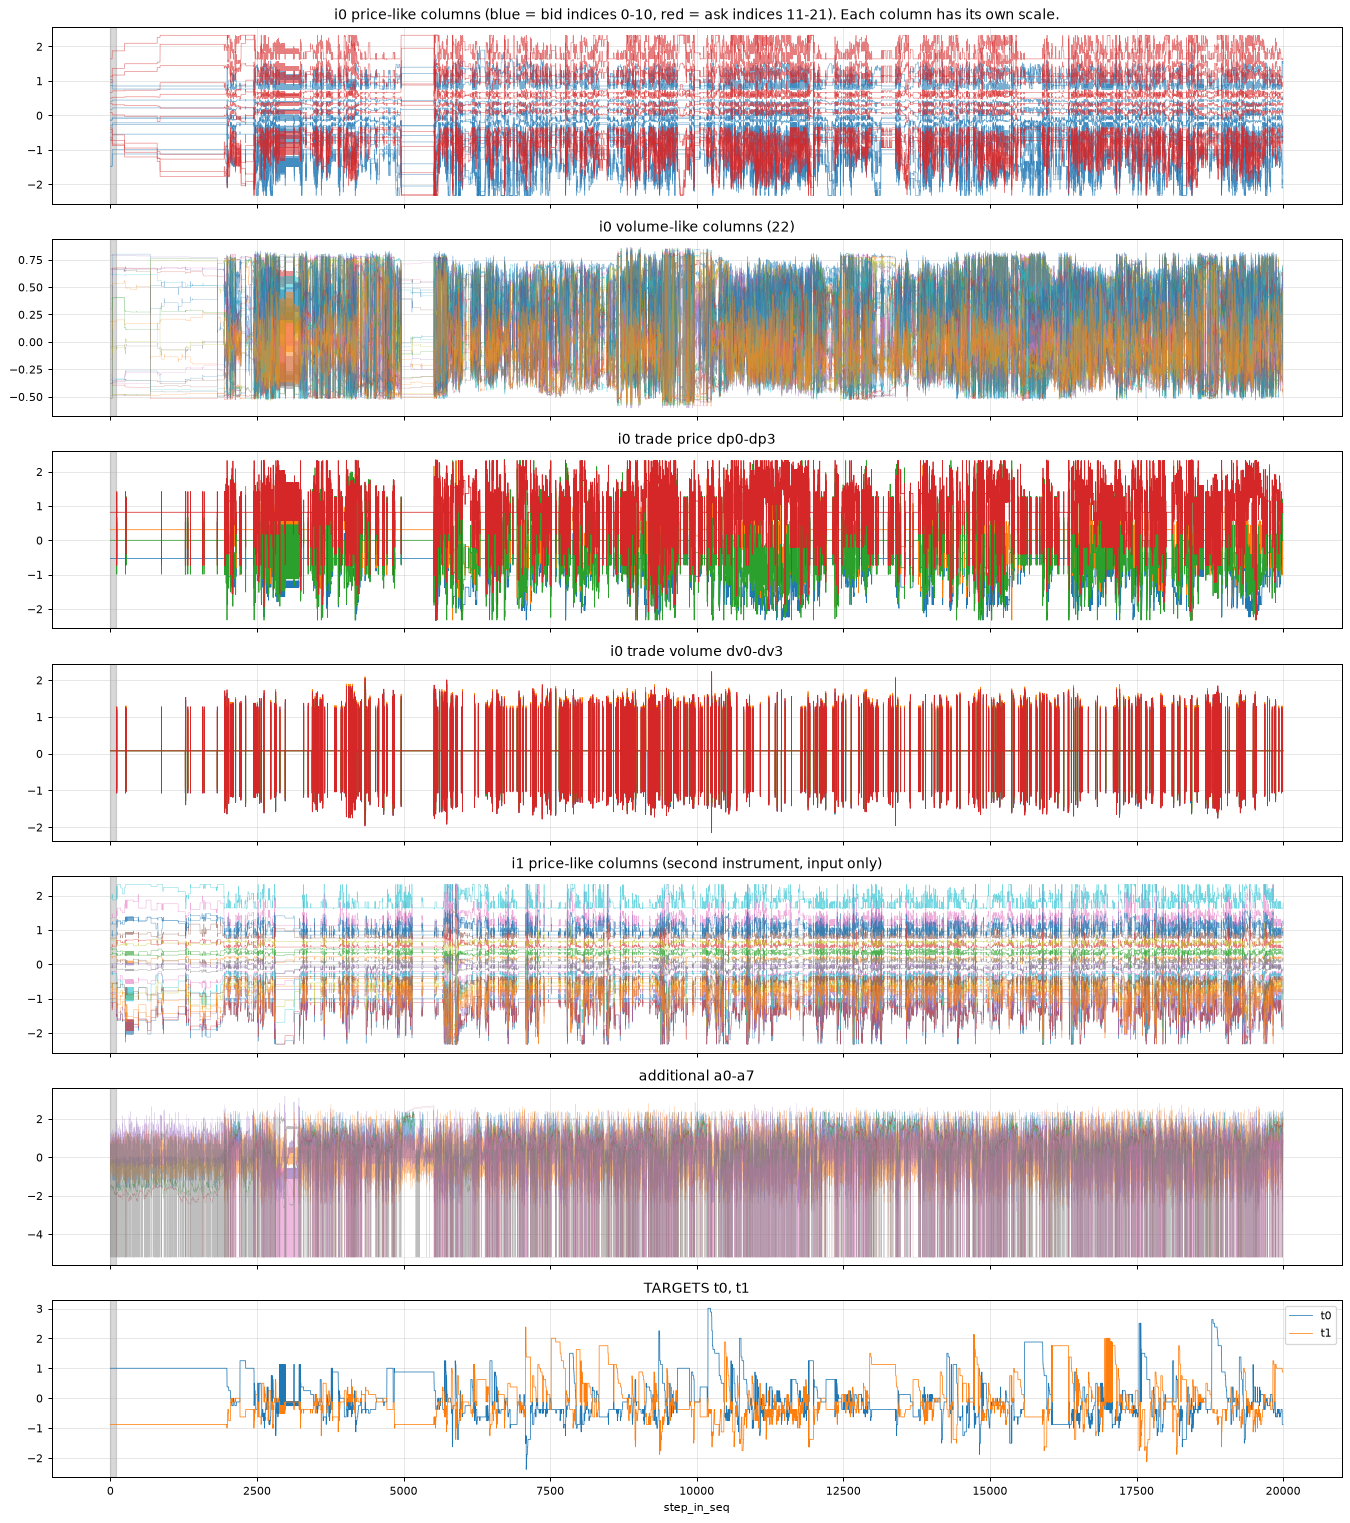

In [3]:
fig, ax = plt.subplots(7, 1, figsize=(15, 17), sharex=True)
s = df.step_in_seq.values
ax[0].plot(s, df[P0[:11]].values, lw=.5, color='tab:blue', alpha=.6); ax[0].plot(s, df[P0[11:]].values, lw=.5, color='tab:red', alpha=.6)
ax[0].set_title('i0 price-like columns (blue = bid indices 0-10, red = ask indices 11-21). Each column has its own scale.')
ax[1].plot(s, df[V0].values, lw=.3, alpha=.5); ax[1].set_title('i0 volume-like columns (22)')
ax[2].plot(s, df[DP0].values, lw=.6); ax[2].set_title('i0 trade price dp0-dp3')
ax[3].plot(s, df[DV0].values, lw=.6); ax[3].set_title('i0 trade volume dv0-dv3')
ax[4].plot(s, df[P1].values, lw=.4, alpha=.6); ax[4].set_title('i1 price-like columns (second instrument, input only)')
ax[5].plot(s, df[A].values, lw=.2, alpha=.5); ax[5].set_title('additional a0-a7')
ax[6].plot(s, df.t0, lw=.6, label='t0'); ax[6].plot(s, df.t1, lw=.6, label='t1'); ax[6].legend(); ax[6].set_title('TARGETS t0, t1')
for a in ax: a.axvspan(0, 98, color='grey', alpha=.3)
ax[-1].set_xlabel('step_in_seq'); plt.tight_layout(); plt.show()

## Step by step: the zoom window
Same groups, but only `START`–`END`. **Dotted vertical lines mark steps where the i0 price block updated.** Check where the targets move: they only ever jump on a dotted line.

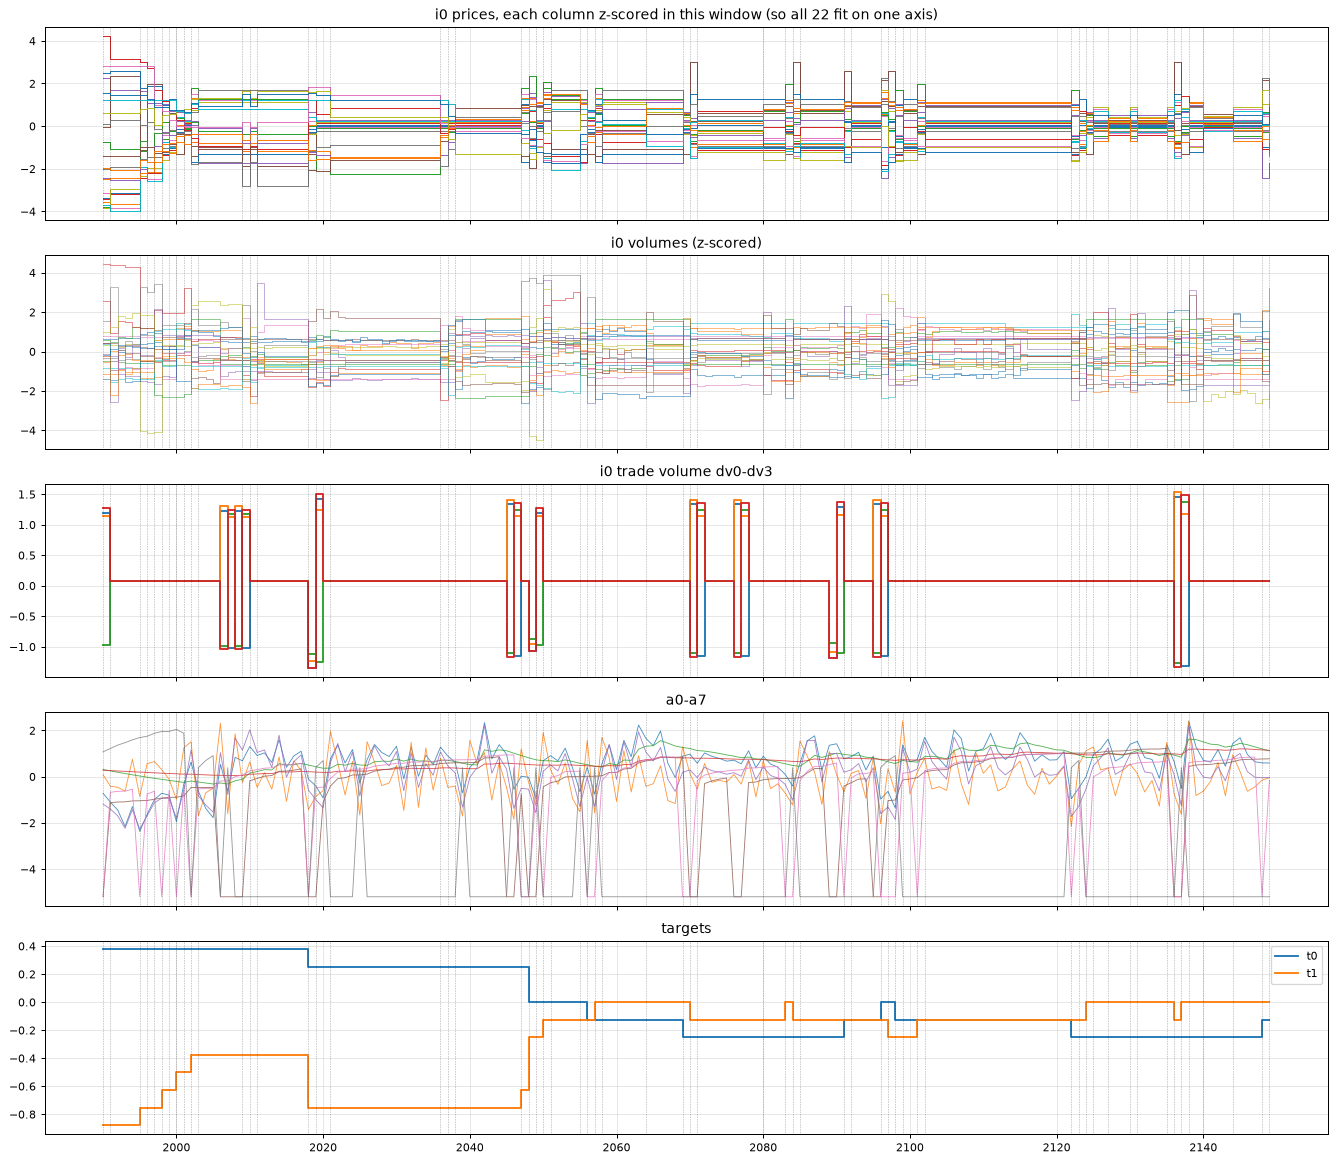

In [4]:
w = df.iloc[START:END]; ws = w.step_in_seq.values; wu = ws[upd[START:END]]
fig, ax = plt.subplots(5, 1, figsize=(15, 13), sharex=True)
z = lambda x: (x - x.mean(0)) / (x.std(0) + 1e-9)
ax[0].plot(ws, z(w[P0].values), drawstyle='steps-post', lw=.8); ax[0].set_title('i0 prices, each column z-scored in this window (so all 22 fit on one axis)')
ax[1].plot(ws, z(w[V0].values), drawstyle='steps-post', lw=.6, alpha=.7); ax[1].set_title('i0 volumes (z-scored)')
ax[2].plot(ws, w[DV0].values, drawstyle='steps-post'); ax[2].set_title('i0 trade volume dv0-dv3')
ax[3].plot(ws, w[A].values, lw=.7, alpha=.8); ax[3].set_title('a0-a7')
ax[4].plot(ws, w.t0, drawstyle='steps-post', label='t0', lw=1.5); ax[4].plot(ws, w.t1, drawstyle='steps-post', label='t1', lw=1.5); ax[4].legend(); ax[4].set_title('targets')
for a in ax:
    for u in wu: a.axvline(u, color='k', ls=':', lw=.5, alpha=.5)
plt.tight_layout(); plt.show()

### Every feature at once, as a heatmap
Rows are the 112 inputs, columns are steps, and colour is the value z-scored over this window. Vertical stripes in the price rows are update events. Volumes and `a*` flicker on almost every step.

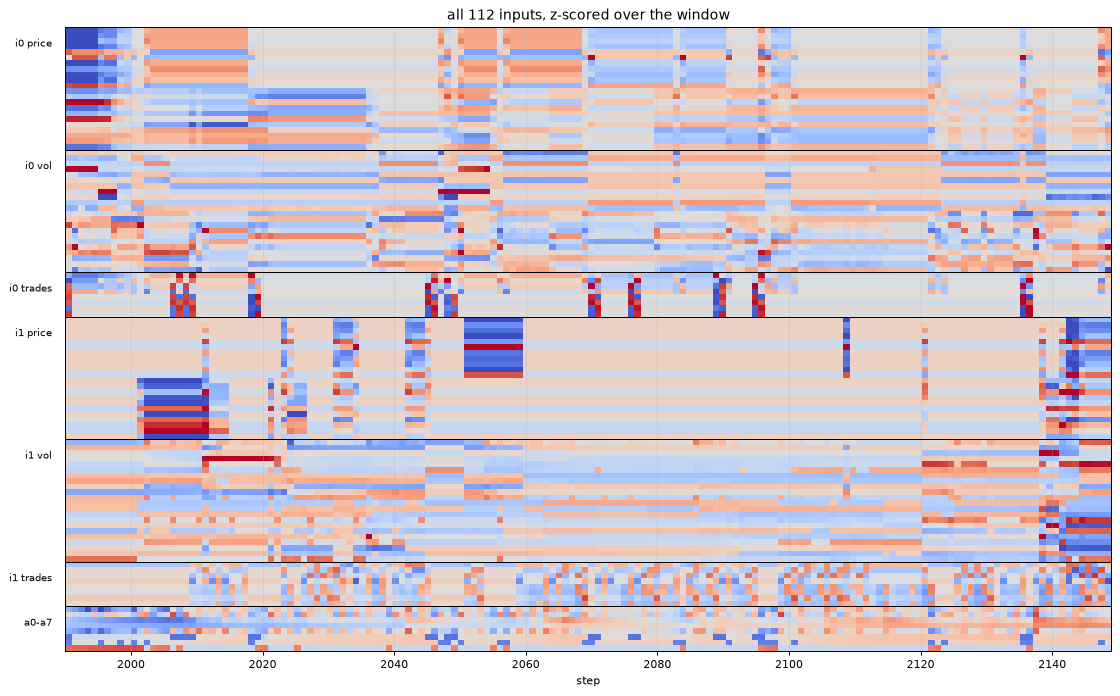

In [5]:
X = z(w[FEATURE_COLUMNS].values).T
fig, ax = plt.subplots(figsize=(15, 9))
ax.imshow(np.clip(X, -3, 3), aspect='auto', cmap='coolwarm', extent=[ws[0], ws[-1], 111.5, -.5], interpolation='nearest')
for y, name in [(0, 'i0 price'), (22, 'i0 vol'), (44, 'i0 trades'), (52, 'i1 price'), (74, 'i1 vol'), (96, 'i1 trades'), (104, 'a0-a7')]:
    ax.axhline(y - .5, color='k', lw=.8); ax.text(ws[0] - 2, y + 3, name, ha='right', fontsize=8)
ax.set_yticks([]); ax.set_xlabel('step'); ax.set_title('all 112 inputs, z-scored over the window'); plt.show()

### How often does each block actually change?

In [6]:
blocks = {'i0 price': P0, 'i0 volume': V0, 'i0 trade price': DP0, 'i0 trade vol': DV0,
          'i1 price': P1, 'i1 volume': V1, 'a0-a7': A, 'targets': ['t0', 't1']}
rate = {k: updates(df, c).mean() for k, c in blocks.items()}
pd.Series(rate).map('{:.1%}'.format).to_frame('share of steps where block changes')

,share of steps where block changes
i0 price,34.1%
i0 volume,76.2%
i0 trade price,33.3%
i0 trade vol,12.0%
i1 price,24.1%
i1 volume,82.6%
a0-a7,100.0%
targets,17.3%


In [7]:
t_change = updates(df, ['t0', 't1'])[1:]
print(f'target changes: {t_change.sum()} steps; of those, {np.mean(upd[1:][t_change]):.1%} are on an i0 price-update step')
print(f'i0 price updates: {upd[1:].sum()} steps; the target changes on {np.mean(t_change[upd[1:]]):.1%} of them')

target changes: 3454 steps; of those, 100.0% are on an i0 price-update step
i0 price updates: 6809 steps; the target changes on 50.7% of them


# Part 2: "depth" (levels 5, 11, 21) and spread

## 2a. The book at one moment
A real order book would look like a staircase: bid prices falling with depth, ask prices rising, and every ask above every bid. Here is what one row actually looks like.

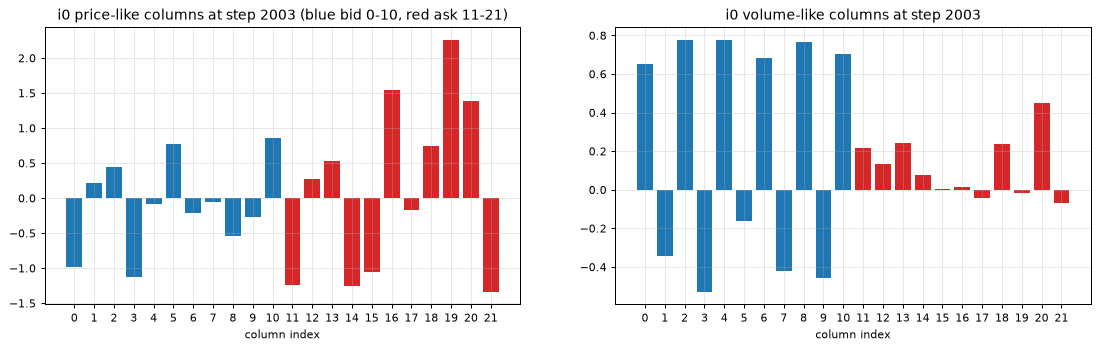

In [8]:
r = df.iloc[STEP]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
c = ['tab:blue'] * 11 + ['tab:red'] * 11
ax[0].bar(range(22), r[P0].values, color=c); ax[0].set_title(f'i0 price-like columns at step {STEP} (blue bid 0-10, red ask 11-21)')
ax[1].bar(range(22), r[V0].values, color=c); ax[1].set_title(f'i0 volume-like columns at step {STEP}')
for a in ax: a.set_xticks(range(22)); a.set_xlabel('column index')
plt.show()

## 2b. Levels 5, 11 and 21 over time
If these were depth levels, they would move together in the same direction, with a fixed gap between them. Here they are over the zoom window and over the full sequence.

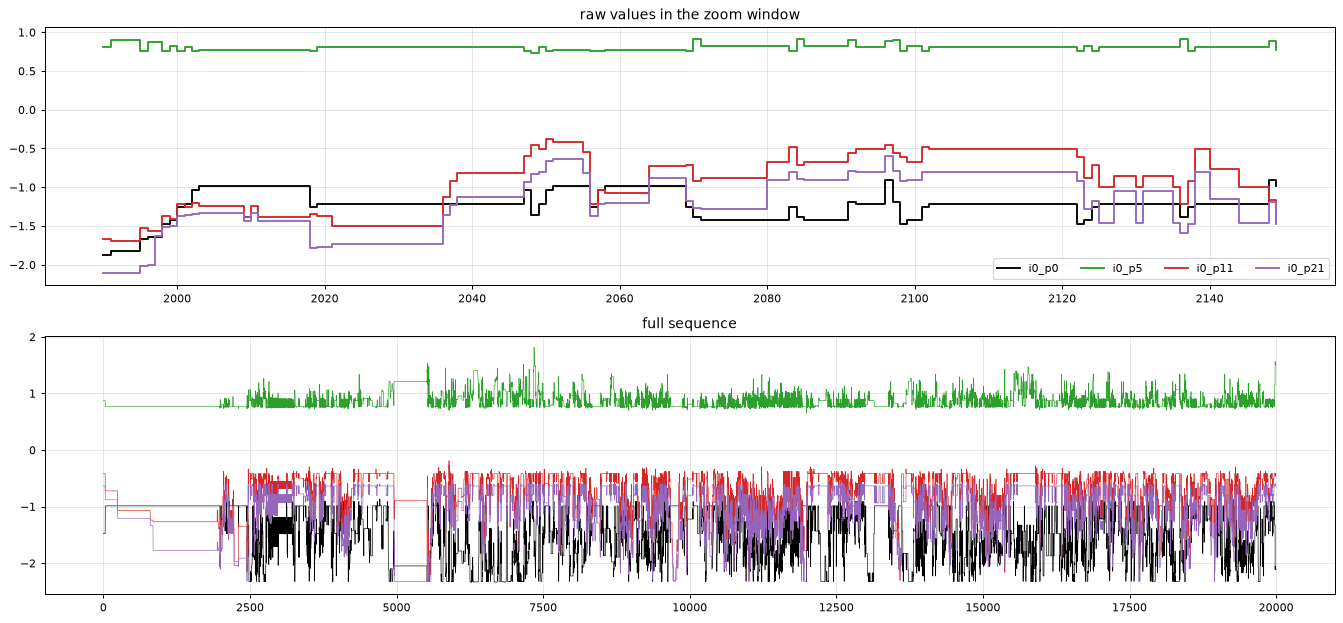

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(15, 7))
for j, col in zip([0, 5, 11, 21], ['k', 'tab:green', 'tab:red', 'tab:purple']):
    ax[0].plot(ws, w[f'i0_p{j}'], drawstyle='steps-post', color=col, label=f'i0_p{j}')
    ax[1].plot(df.step_in_seq, df[f'i0_p{j}'], lw=.5, color=col, label=f'i0_p{j}')
ax[0].set_title('raw values in the zoom window'); ax[1].set_title('full sequence'); ax[0].legend(ncol=4); plt.tight_layout(); plt.show()

## 2c. Tests: is this a real order book?

In [10]:
P = df[P0].to_numpy(); d = np.diff(P, axis=0)
n_changed = (d != 0).sum(1)
checks = {
  'rows where bid columns 0-10 are sorted (either direction)': np.mean(np.all(np.diff(P[:, :11], axis=1) <= 0, 1) | np.all(np.diff(P[:, :11], axis=1) >= 0, 1)),
  'rows where ask columns 11-21 are sorted (either direction)': np.mean(np.all(np.diff(P[:, 11:], axis=1) <= 0, 1) | np.all(np.diff(P[:, 11:], axis=1) >= 0, 1)),
  'rows where every ask column > every bid column': np.mean(P[:, :11].max(1) < P[:, 11:].min(1)),
  'price updates where ALL 22 columns change at once': np.mean(n_changed[n_changed > 0] == 22),
}
for k, v in checks.items(): print(f'{v:7.1%}  {k}')
print('distinct values per column in this sequence:', [len(np.unique(P[:, j])) for j in range(22)])

   0.0%  rows where bid columns 0-10 are sorted (either direction)
   0.0%  rows where ask columns 11-21 are sorted (either direction)
   0.0%  rows where every ask column > every bid column
  81.6%  price updates where ALL 22 columns change at once
distinct values per column in this sequence: [526, 526, 526, 526, 526, 526, 526, 526, 526, 526, 526, 483, 483, 483, 483, 483, 483, 483, 483, 483, 483, 483]


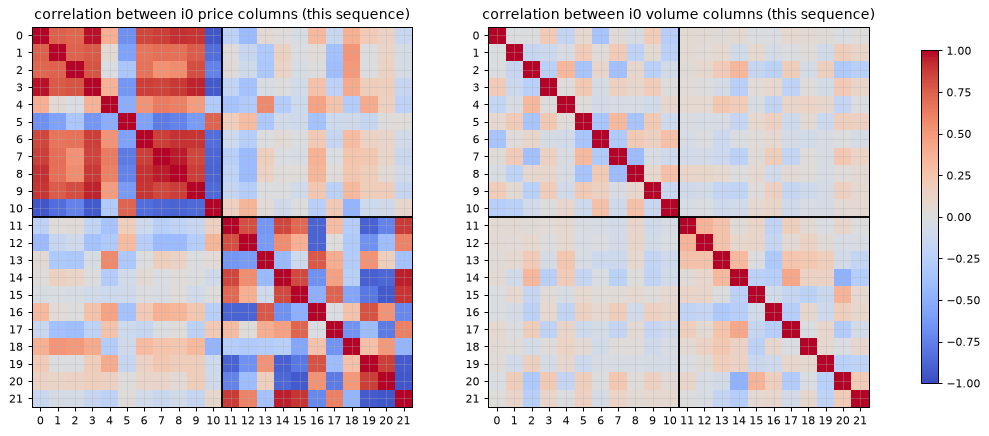

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, cols, t in [(ax[0], P0, 'i0 price columns'), (ax[1], V0, 'i0 volume columns')]:
    C = np.corrcoef(df[cols].to_numpy().T)
    im = a.imshow(C, cmap='coolwarm', vmin=-1, vmax=1); a.set_title(f'correlation between {t} (this sequence)')
    a.set_xticks(range(22)); a.set_yticks(range(22)); a.axhline(10.5, color='k'); a.axvline(10.5, color='k')
plt.colorbar(im, ax=ax, shrink=.8); plt.show()

## 2d. How many independent signals are inside the 22 price columns?
PCA on the *changes* of the 22 price columns, measured on update steps only. If one component explains nearly everything, the 22 columns are really **one price movement seen through 22 different linear "lenses"** (scaled, shifted, sometimes sign-flipped), not 22 depth levels.

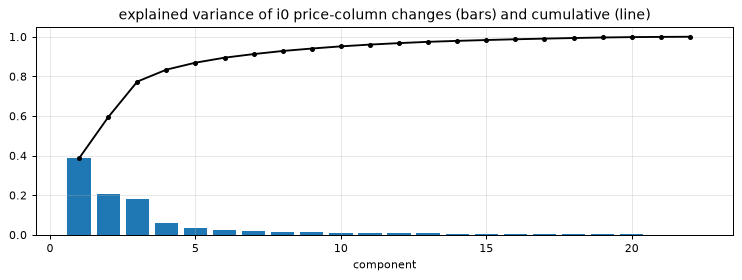

first 5 components: [0.386 0.207 0.18  0.06  0.035] | cumulative: [0.386 0.594 0.773 0.834 0.869]


In [12]:
from sklearn.decomposition import PCA
dU = d[n_changed > 0]
pca = PCA().fit((dU - dU.mean(0)) / (dU.std(0) + 1e-12))
ev = pca.explained_variance_ratio_
plt.figure(figsize=(10, 3)); plt.bar(range(1, 23), ev); plt.plot(range(1, 23), np.cumsum(ev), 'k.-')
plt.title('explained variance of i0 price-column changes (bars) and cumulative (line)'); plt.xlabel('component'); plt.show()
print('first 5 components:', np.round(ev[:5], 3), '| cumulative:', np.round(np.cumsum(ev)[:5], 3))

## 2e. "Spread"
Since no column is the best bid or the best ask, we can't compute a true spread (best ask minus best bid). Our engineered "spread" (`f1`) is **mean of ask columns minus mean of bid columns**. It's a linear mixture of unknown meaning. Here is how it moves, and how a PCA-based "price" moves.

C:\Users\Shariq\AppData\Local\Temp\ipykernel_36628\3652897894.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  spread_proxy = df[P0[11:]].mean(1) - df[P0[:11]].mean(1)
C:\Users\Shariq\AppData\Local\Temp\ipykernel_36628\3652897894.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  spread_proxy = df[P0[11:]].mean(1) - df[P0[:11]].mean(1)


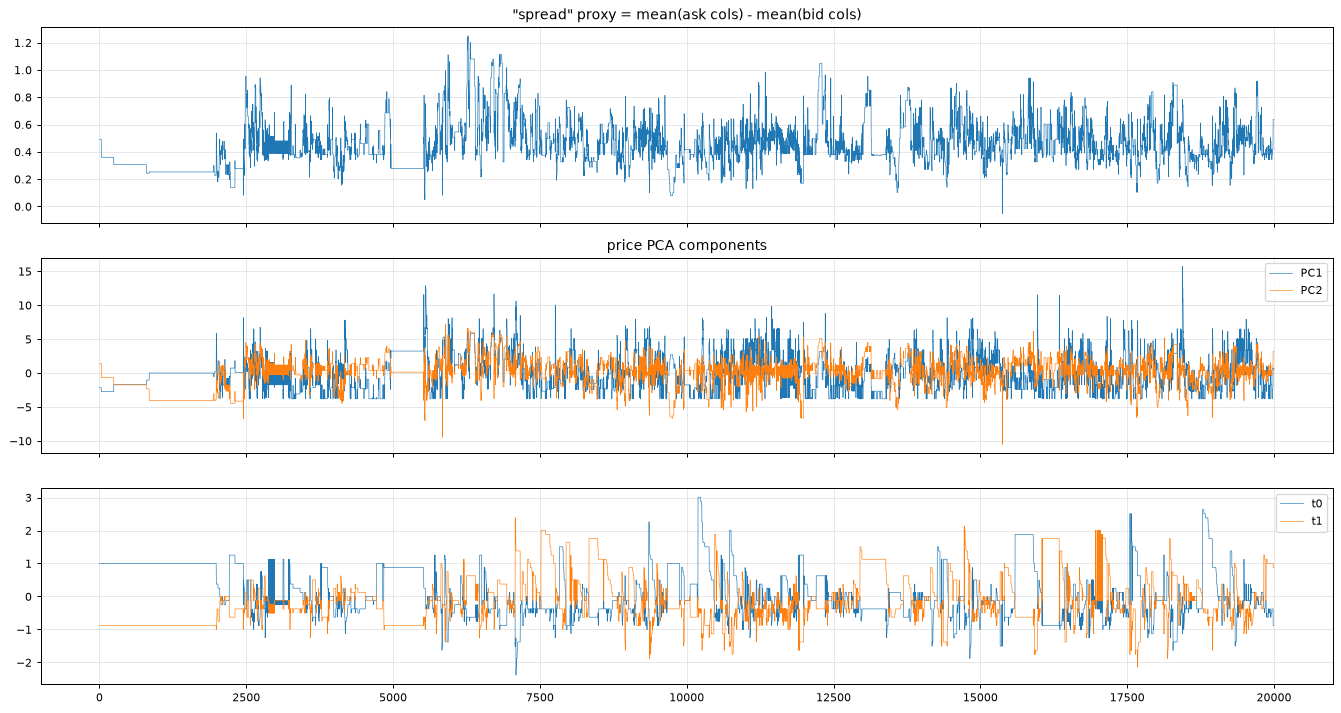

spread proxy   corr with t0 -0.417   t1 +0.302
PC1 level      corr with t0 -0.144   t1 -0.192
PC2 level      corr with t0 -0.408   t1 +0.362


In [13]:
spread_proxy = df[P0[11:]].mean(1) - df[P0[:11]].mean(1)
Pz = (P - P.mean(0)) / (P.std(0) + 1e-12)
pc = Pz @ pca.components_[:2].T          # PC1 ~ "the price", PC2 = next strongest pattern
fig, ax = plt.subplots(3, 1, figsize=(15, 8), sharex=True)
ax[0].plot(df.step_in_seq, spread_proxy, lw=.5); ax[0].set_title('"spread" proxy = mean(ask cols) - mean(bid cols)')
ax[1].plot(df.step_in_seq, pc[:, 0], lw=.5, label='PC1'); ax[1].plot(df.step_in_seq, pc[:, 1], lw=.5, label='PC2'); ax[1].legend(); ax[1].set_title('price PCA components')
ax[2].plot(df.step_in_seq, df.t0, lw=.5, label='t0'); ax[2].plot(df.step_in_seq, df.t1, lw=.5, label='t1'); ax[2].legend()
plt.tight_layout(); plt.show()
m = df.need_prediction.values
for name, x in [('spread proxy', spread_proxy.values), ('PC1 level', pc[:, 0]), ('PC2 level', pc[:, 1])]:
    print(f'{name:13s}  corr with t0 {np.corrcoef(x[m], df.t0[m])[0,1]:+.3f}   t1 {np.corrcoef(x[m], df.t1[m])[0,1]:+.3f}')

# Part 3: what features are there?

## 3a. The 112 raw inputs
| Block | Columns | Count | Behaviour (see the change-rate table above) |
|---|---|---:|---|
| i0 price-like | `i0_p0..p21` | 22 | all change together, only on update steps; mixed "lenses" on one price |
| i0 volume-like | `i0_v0..v21` | 22 | change much more often than prices |
| i0 trades | `i0_dp0..3`, `i0_dv0..3` | 8 | last-trade information; holds between trades |
| i1 | same layout | 52 | second instrument, has no targets |
| additional | `a0..a7` | 8 | change nearly every step, noisy |

## 3b. Our engineered sets
| Set | Size | What it adds | Result on full valid |
|---|---:|---|---|
| `raw` | 112 | nothing | about the same as v144 |
| `v144` | 144 | 32 hand features: "spread", "mid", imbalances, return/OFI EMAs, cross-instrument | 0.6794 (norm_ft 0.6815) |
| `raw_ev_ema` | 456 | update flags, steps-since-update, 1-step diffs, x minus EMA(0.05) and x minus EMA(0.005) | 0.6809 |
| ensemble v144 + raw_ev_ema | — | two different input views averaged | **0.6845** valid, **0.65539** platform |

The feature audit (`runs/feature_audit.py`) found that **14 of the 32 engineered features are exact linear functions of the raw row**, so a network gets them for free from its first layer. Most of the "book" features (spread, mid, L0/L2/L4/L10 imbalance) assume that the index is a depth level, and Part 2 showed it isn't.

## 3c. Which raw inputs carry signal (current row only)?
|t|-weighted correlation of each raw input with each target, pooled over 40 train sequences. This uses only the current row, with no history.

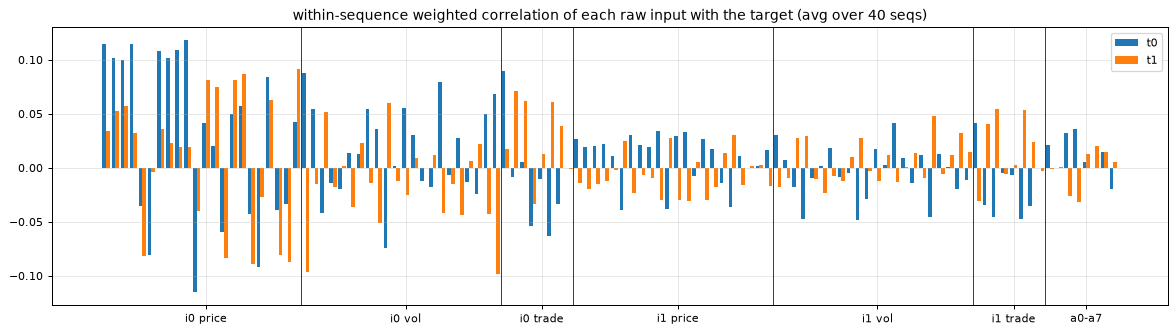

C:\Users\Shariq\AppData\Local\Temp\ipykernel_36628\3816990639.py:17: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  corr.assign(abs_mean=corr.abs().mean(1)).sort_values('abs_mean', ascending=False).head(15).round(3)


,t0,t1,abs_mean
i0_v0,0.088,-0.096,0.092
i0_v21,0.068,-0.099,0.083
i0_p2,0.100,0.057,0.079
i0_p10,-0.115,-0.040,0.077
i0_p1,0.102,0.053,0.077
i0_p0,0.115,0.034,0.074
i0_p3,0.115,0.032,0.074
i0_p18,0.084,0.062,0.073
i0_p6,0.108,0.036,0.072
i0_p15,0.057,0.087,0.072


In [14]:
rng = np.random.default_rng(0)
cols = FEATURE_COLUMNS + ['t0', 't1', 'need_prediction']
acc = np.zeros((112, 2)); N = 0
for i in rng.choice(TRAIN.num_row_groups, 40, replace=False):
    s_ = load_seq(int(i), cols=cols); s_ = s_[s_.need_prediction]
    X_ = s_[FEATURE_COLUMNS].to_numpy(np.float64); X_ = (X_ - X_.mean(0)) / (X_.std(0) + 1e-12)
    for k, t in enumerate(['t0', 't1']):
        y = np.clip(s_[t].to_numpy(np.float64), -2, 2); wt = np.abs(y); yc = y - np.average(y, weights=wt)
        acc[:, k] += (wt[:, None] * yc[:, None] * X_).sum(0) / np.sqrt((wt * yc**2).sum() * (wt[:, None] * X_**2).sum(0))
    N += 1
corr = pd.DataFrame(acc / N, index=FEATURE_COLUMNS, columns=['t0', 't1'])
fig, ax = plt.subplots(figsize=(16, 4))
ax.bar(np.arange(112) - .2, corr.t0, .4, label='t0'); ax.bar(np.arange(112) + .2, corr.t1, .4, label='t1')
for x0 in [22, 44, 52, 74, 96, 104]: ax.axvline(x0 - .5, color='k', lw=.6)
ax.set_xticks([11, 33, 48, 63, 85, 100, 108]); ax.set_xticklabels(['i0 price', 'i0 vol', 'i0 trade', 'i1 price', 'i1 vol', 'i1 trade', 'a0-a7'])
ax.legend(); ax.set_title('within-sequence weighted correlation of each raw input with the target (avg over 40 seqs)'); plt.show()
corr.assign(abs_mean=corr.abs().mean(1)).sort_values('abs_mean', ascending=False).head(15).round(3)

# Part 4: the targets and the noise

## 4a. What the targets look like

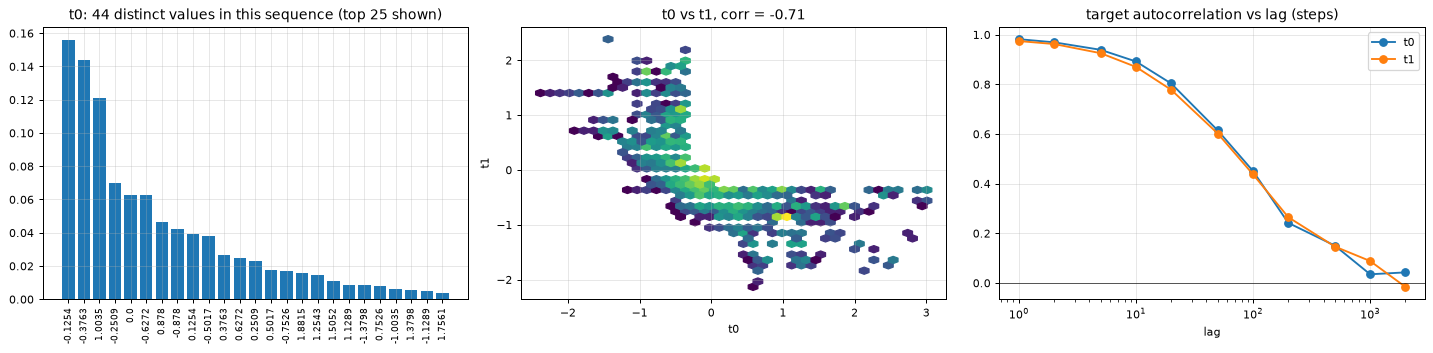

In [15]:
m = df.need_prediction.values
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
vals, cnt = np.unique(np.round(df.t0[m], 4), return_counts=True)
top = np.argsort(cnt)[::-1][:25]
ax[0].bar(range(25), cnt[top] / cnt.sum()); ax[0].set_xticks(range(25)); ax[0].set_xticklabels(vals[top], rotation=90, fontsize=7)
ax[0].set_title(f't0: {len(vals)} distinct values in this sequence (top 25 shown)')
ax[1].hexbin(df.t0[m], df.t1[m], gridsize=40, bins='log', cmap='viridis'); ax[1].set_xlabel('t0'); ax[1].set_ylabel('t1')
ax[1].set_title(f't0 vs t1, corr = {np.corrcoef(df.t0[m], df.t1[m])[0,1]:.2f}')
lags = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000]
y = df.t0[m].to_numpy()
ax[2].semilogx(lags, [np.corrcoef(y[:-L], y[L:])[0, 1] for L in lags], 'o-', label='t0')
y = df.t1[m].to_numpy(); ax[2].semilogx(lags, [np.corrcoef(y[:-L], y[L:])[0, 1] for L in lags], 'o-', label='t1')
ax[2].axhline(0, color='k', lw=.5); ax[2].set_title('target autocorrelation vs lag (steps)'); ax[2].legend(); ax[2].set_xlabel('lag')
plt.tight_layout(); plt.show()

## 4b. Run our best model on validation sequences
This is the platform-best ensemble (v144 norm_ft plus raw_ev_ema, platform 0.65539), run on 150 random validation sequences with the official mask. It takes about a minute on GPU.

In [16]:
import torch
from src.evaluate import load_pytorch_model
from src.feature_sets import build_features
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CKPTS = ['checkpoints_norm_ft/best_norm_ft.pt', 'checkpoints_raw_ev_ema_s21/best.pt']
models = [(load_pytorch_model(Path(c), dev), torch.load(c, map_location='cpu').get('model_config', {}).get('feature_set', 'v144')) for c in CKPTS]

def predict(raw):
    out = []
    with torch.no_grad():
        for mdl, fs in models:
            x = torch.from_numpy(build_features(raw, fs)).unsqueeze(0).to(dev)
            out.append(mdl(x)[0][0].float().cpu().numpy())
    return np.mean(out, 0)

VSEQ = np.sort(np.random.default_rng(1).choice(VALID.num_row_groups, 150, replace=False))
vcols = FEATURE_COLUMNS + ['t0', 't1', 'need_prediction', 'is_scored']
Y, PR, MASK, UPD, PC1 = [], [], [], [], []
for i in VSEQ:
    v = load_seq(int(i), 'valid', vcols)
    raw = v[FEATURE_COLUMNS].to_numpy(np.float32)
    Y.append(v[['t0', 't1']].to_numpy(np.float32)); PR.append(predict(raw))
    MASK.append(v.need_prediction.values & v.is_scored.values); UPD.append(updates(v))
    PC1.append(raw[:, :22].mean(1))   # crude price level, used for the past/future-move check below
Y, PR, MASK, UPD = map(np.stack, (Y, PR, MASK, UPD))
Ym, Pm = Y[MASK], PR[MASK]
print(f'{len(VSEQ)} valid sequences, {MASK.sum():,} scored rows ({MASK.mean():.1%} of rows)')
print(f'WP on this sample: t0 {wp(Ym[:,0], Pm[:,0]):.4f}  t1 {wp(Ym[:,1], Pm[:,1]):.4f}  mean {(wp(Ym[:,0], Pm[:,0]) + wp(Ym[:,1], Pm[:,1]))/2:.4f}')

150 valid sequences, 257,348 scored rows (8.6% of rows)
WP on this sample: t0 0.6811  t1 0.6879  mean 0.6845


## 4c. Prediction vs truth, step by step
Black is the true target, orange is our prediction, and dots mark the scored rows. Pick a sequence `K` (0–149) and a window.

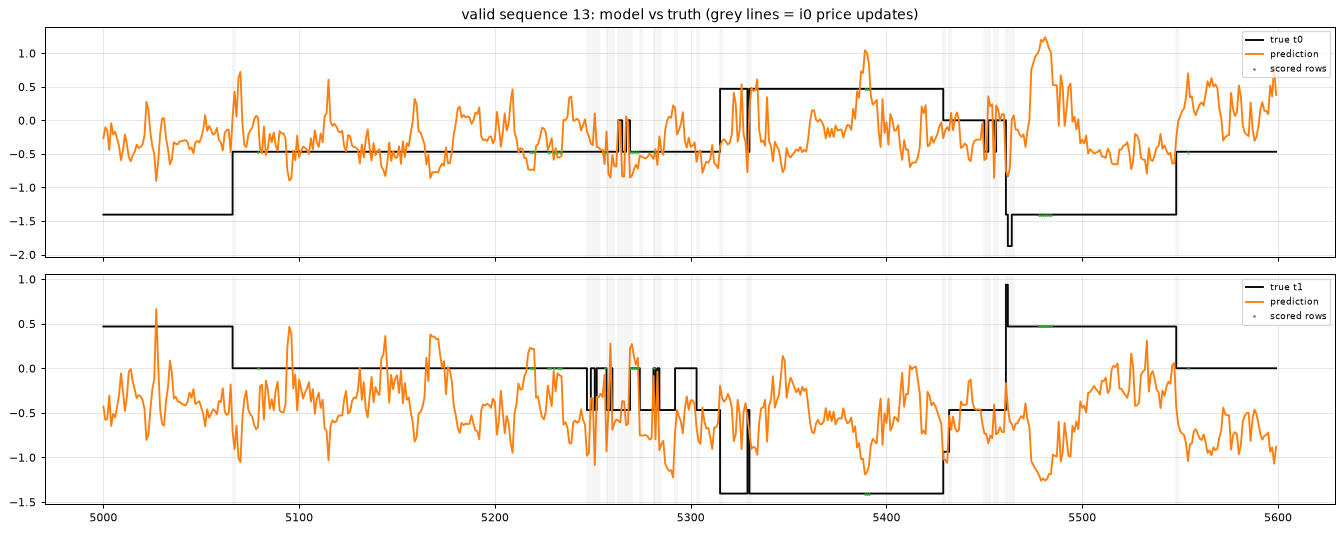

In [17]:
K, A0, A1 = 0, 5000, 5600
fig, ax = plt.subplots(2, 1, figsize=(15, 6), sharex=True)
st = np.arange(20000)[A0:A1]
for j, a in enumerate(ax):
    a.plot(st, Y[K, A0:A1, j], 'k', drawstyle='steps-post', label=f'true t{j}')
    a.plot(st, PR[K, A0:A1, j], color='tab:orange', label='prediction')
    sc = MASK[K, A0:A1]; a.plot(st[sc], Y[K, A0:A1, j][sc], '.', ms=2, color='tab:green', label='scored rows')
    for u in st[UPD[K, A0:A1]]: a.axvline(u, color='grey', lw=.3, alpha=.4)
    a.legend(loc='upper right', fontsize=7)
ax[0].set_title(f'valid sequence {VSEQ[K]}: model vs truth (grey lines = i0 price updates)'); plt.tight_layout(); plt.show()

## 4d. Noise, measured several ways

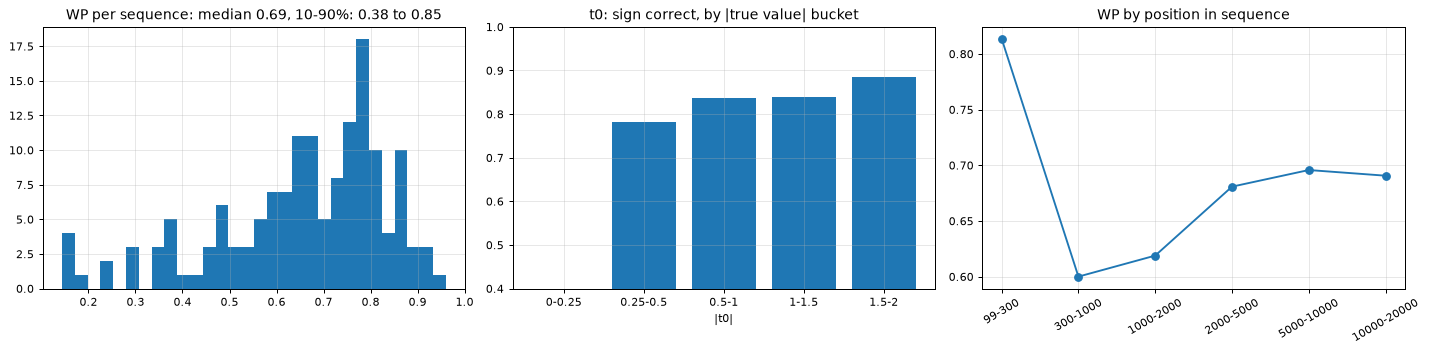

WP ~ 0.685 means the model explains about 47% of the (weighted) target variance; about 53% is still unexplained.


In [18]:
def seq_wp(k):
    mk = MASK[k]
    return np.mean([wp(Y[k, mk, j], PR[k, mk, j]) for j in range(2)]) if mk.sum() > 50 else np.nan
per_seq = np.array([seq_wp(k) for k in range(len(VSEQ))])

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(per_seq[~np.isnan(per_seq)], 30); ax[0].set_title(f'WP per sequence: median {np.nanmedian(per_seq):.2f}, 10-90%: {np.nanpercentile(per_seq,10):.2f} to {np.nanpercentile(per_seq,90):.2f}')

# WP by |target| bucket: how well do we track big vs small values?
bins = [0, .25, .5, 1, 1.5, 2.01]; ya = np.abs(np.clip(Ym[:, 0], -2, 2))
ax[1].bar(range(5), [np.mean(np.sign(Pm[(ya >= lo) & (ya < hi), 0]) == np.sign(Ym[(ya >= lo) & (ya < hi), 0])) for lo, hi in zip(bins, bins[1:])])
ax[1].set_xticks(range(5)); ax[1].set_xticklabels([f'{lo}-{hi:.0f}' if hi > 2 else f'{lo}-{hi}' for lo, hi in zip(bins, bins[1:])])
ax[1].set_ylim(.4, 1); ax[1].set_title('t0: sign correct, by |true value| bucket'); ax[1].set_xlabel('|t0|')

# does the model get better deeper into the sequence (more history)?
edges = [99, 300, 1000, 2000, 5000, 10000, 20000]
ax[2].plot(range(len(edges) - 1), [np.mean([wp(Y[:, a:b, j][MASK[:, a:b]], PR[:, a:b, j][MASK[:, a:b]]) for j in range(2)]) for a, b in zip(edges, edges[1:])], 'o-')
ax[2].set_xticks(range(len(edges) - 1)); ax[2].set_xticklabels([f'{a}-{b}' for a, b in zip(edges, edges[1:])], rotation=30)
ax[2].set_title('WP by position in sequence'); plt.tight_layout(); plt.show()

r2 = np.mean([wp(Ym[:, j], Pm[:, j]) for j in range(2)]) ** 2
print(f'WP ~ {np.sqrt(r2):.3f} means the model explains about {r2:.0%} of the (weighted) target variance; about {1-r2:.0%} is still unexplained.')

### How noisy is the score itself?
The test set is 1,970 sequences. Below we resample sequences (bootstrap) to see how much a score moves just from *which* sequences are in the test set. Same model, different draw of sequences.

bootstrap std of WP with 150 sequences: 0.0184  -> scaled to 1,970 test sequences: ~0.0051


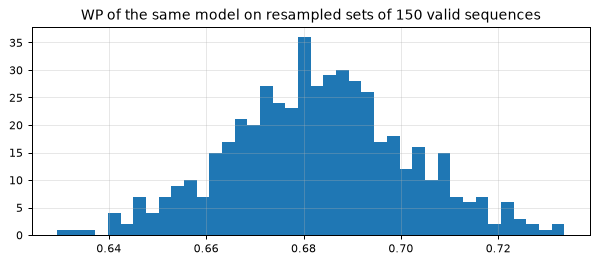

In [19]:
def suff(k):
    # per-sequence sufficient statistics for the global weighted Pearson
    mk = MASK[k]; out = []
    for j in range(2):
        y = np.clip(Y[k, mk, j].astype(np.float64), -2, 2); p = np.clip(PR[k, mk, j].astype(np.float64), -2, 2); w_ = np.abs(y)
        out.append([w_.sum(), (w_*y).sum(), (w_*p).sum(), (w_*y*y).sum(), (w_*p*p).sum(), (w_*y*p).sum()])
    return np.array(out)
S = np.stack([suff(k) for k in range(len(VSEQ))])          # (seq, target, 6)
def wp_from(Ss):
    W, Sy, Sp, Syy, Spp, Syp = Ss.sum(0).T
    cov = Syp - Sy*Sp/W; vy = Syy - Sy**2/W; vp = Spp - Sp**2/W
    return np.mean(cov / np.sqrt(vy*vp))
boot = [wp_from(S[np.random.default_rng(b).integers(0, len(VSEQ), len(VSEQ))]) for b in range(500)]
sd150 = np.std(boot); sd1970 = sd150 * np.sqrt(len(VSEQ) / 1970)
print(f'bootstrap std of WP with 150 sequences: {sd150:.4f}  -> scaled to 1,970 test sequences: ~{sd1970:.4f}')
plt.figure(figsize=(8, 3)); plt.hist(boot, 40); plt.title('WP of the same model on resampled sets of 150 valid sequences'); plt.show()

### Is the target about the past or the future?
The targets are described as "indicators of future price movement". If they really are about the future, they should correlate with how the (crude) price moves *after* step t, and we can't see that at prediction time. Correlation with the *past* move is what's learnable.

In [20]:
H = [1, 10, 100, 1000]; res = {}
for h in H:
    fut, past = [], []
    for k in range(len(VSEQ)):
        p_ = PC1[k]; idx = np.arange(1000, 20000 - 1000)
        fut.append(np.corrcoef(Y[k, idx, 0], p_[idx + h] - p_[idx])[0, 1]); past.append(np.corrcoef(Y[k, idx, 0], p_[idx] - p_[idx - h])[0, 1])
    res[h] = (np.nanmean(past), np.nanmean(fut))
pd.DataFrame(res, index=['corr(t0, past move over h)', 'corr(t0, future move over h)']).round(3)

,1,10,100,1000
"corr(t0, past move over h)",0.053,0.078,0.098,0.110
"corr(t0, future move over h)",-0.054,-0.067,-0.093,-0.116


# Part 5: why we can't get past ~0.68

## 5a. Everything we tried, side by side
All numbers are full-valid WP (1,873 sequences) unless marked. Sources are `runs/*.log` and `docs/wunder_challenge_report.md`.

In [21]:
exp = pd.DataFrame([
  ('LightGBM, current row only (no history)',      0.624,  'runs/nowcast_probe.log (157 valid seqs)'),
  ('LightGBM, current row + EMA history',          0.630,  'runs/history_probe.log'),
  ('Starter baseline (validation)',                0.617,  'README'),
  ('v5 GRU (platform 0.65207)',                    0.6794, 'memory / report'),
  ('norm_ft GRU, v144 (platform 0.65191)',         0.6815, 'runs/norm_ft.log'),
  ('Bigger models H128x3 / H192 / H256 (2-ep screen)', 0.666, 'screen: all 0.664-0.666, same as H128x2'),
  ('raw_ev_ema GRU (456 features)',                0.6809, 'runs/full_raw_ev_ema_s21.log'),
  ('Ensemble v144 + raw_ev_ema (platform 0.65539)', 0.6845, 'runs/ens_feat_diverse.log'),
  ('+ event post-processing',                       None,  'worse: runs/postproc_probe.log'),
  ('+ LightGBM blend',                              None,  'no gain: runs/blend_probe.log'),
], columns=['experiment', 'valid WP', 'source'])
exp

,experiment,valid WP,source
0,"LightGBM, current row only (no history)",0.6240,runs/nowcast_probe.log (157 valid seqs)
1,"LightGBM, current row + EMA history",0.6300,runs/history_probe.log
2,Starter baseline (validation),0.6170,README
3,v5 GRU (platform 0.65207),0.6794,memory / report
4,"norm_ft GRU, v144 (platform 0.65191)",0.6815,runs/norm_ft.log
5,Bigger models H128x3 / H192 / H256 (2-ep screen),0.6660,"screen: all 0.664-0.666, same as H128x2"
6,raw_ev_ema GRU (456 features),0.6809,runs/full_raw_ev_ema_s21.log
7,Ensemble v144 + raw_ev_ema (platform 0.65539),0.6845,runs/ens_feat_diverse.log
8,+ event post-processing,NaN,worse: runs/postproc_probe.log
9,+ LightGBM blend,NaN,no gain: runs/blend_probe.log


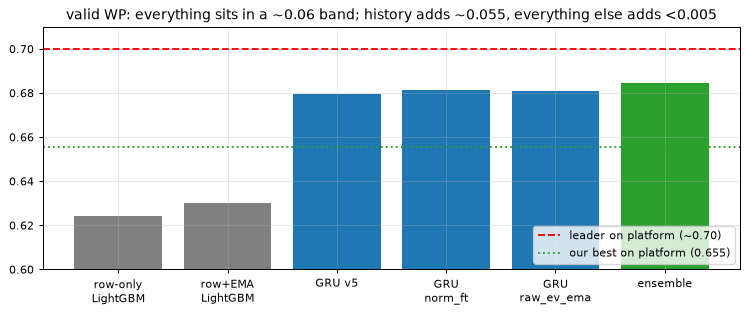

In [22]:
labels = ['row-only\nLightGBM', 'row+EMA\nLightGBM', 'GRU v5', 'GRU\nnorm_ft', 'GRU\nraw_ev_ema', 'ensemble']
vals = [0.624, 0.630, 0.6794, 0.6815, 0.6809, 0.6845]
plt.figure(figsize=(10, 3.5)); b = plt.bar(labels, vals, color=['grey', 'grey', 'tab:blue', 'tab:blue', 'tab:blue', 'tab:green'])
plt.axhline(0.70, color='r', ls='--', label='leader on platform (~0.70)'); plt.axhline(0.65539, color='tab:green', ls=':', label='our best on platform (0.655)')
plt.ylim(.6, .71); plt.legend(loc='lower right'); plt.title('valid WP: everything sits in a ~0.06 band; history adds ~0.055, everything else adds <0.005'); plt.show()

## 5b. Is anything left in the residual?
We train a fresh LightGBM to predict the **error** of our ensemble (truth minus prediction) from the current inputs plus our prediction. If it can predict the error on held-out sequences, there is signal we are missing. If it can't, the rest is noise *from the point of view of these inputs*.

In [23]:
import lightgbm as lgb
feats, tgt, grp = [], [], []
for k, i in enumerate(VSEQ):
    v = load_seq(int(i), 'valid', FEATURE_COLUMNS)
    F = build_features(v[FEATURE_COLUMNS].to_numpy(np.float32), 'raw_ev_ema')
    mk = np.where(MASK[k])[0][::3]
    feats.append(np.hstack([F[mk], PR[k, mk]])); tgt.append(Y[k, mk] - PR[k, mk]); grp.append(np.full(len(mk), k))
Fx, R, G = np.vstack(feats), np.vstack(tgt), np.concatenate(grp)
tr, te = G < 100, G >= 100
gain = []
for j in range(2):
    mdl = lgb.LGBMRegressor(n_estimators=300, learning_rate=.05, num_leaves=63, subsample=.8, subsample_freq=1, colsample_bytree=.5, verbose=-1)
    mdl.fit(Fx[tr], R[tr, j], sample_weight=np.abs(np.clip(R[tr, j] + Fx[tr, -2 + j], -2, 2)) + 1e-3)
    base_p = Fx[te, -2 + j]; ytrue = R[te, j] + base_p
    gain.append((wp(ytrue, base_p), wp(ytrue, base_p + mdl.predict(Fx[te]))))
for j, (b0, b1) in enumerate(gain): print(f't{j}: ensemble {b0:.4f} -> ensemble + residual model {b1:.4f}  (change {b1-b0:+.4f})')

t0: ensemble 0.6378 -> ensemble + residual model 0.6238  (change -0.0140)
t1: ensemble 0.6824 -> ensemble + residual model 0.6502  (change -0.0323)


## 5c. Train vs validation vs test are different periods

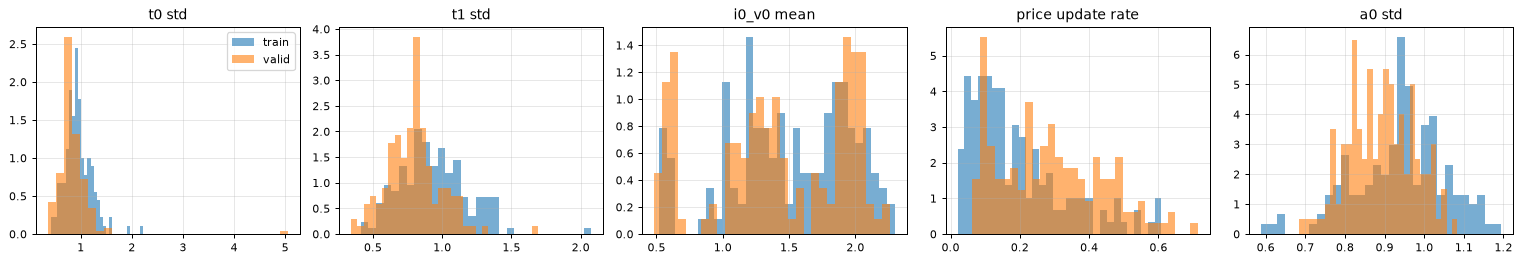

,train mean,valid mean
t0 std,0.954,0.842
t1 std,0.939,0.796
i0_v0 mean,1.502,1.421
price update rate,0.192,0.289
a0 std,0.940,0.891


In [24]:
def seq_stats(pf, ids):
    out = []
    for i in ids:
        s_ = pf.read_row_group(int(i), columns=['t0', 't1', 'i0_v0', 'i0_p0', 'a0']).to_pandas()
        x = s_['i0_p0'].to_numpy(); out.append((s_.t0.std(), s_.t1.std(), s_.i0_v0.mean(), np.mean(x[1:] != x[:-1]), s_.a0.std()))
    return pd.DataFrame(out, columns=['t0 std', 't1 std', 'i0_v0 mean', 'price update rate', 'a0 std'])
rng = np.random.default_rng(2)
tr_s = seq_stats(TRAIN, rng.choice(TRAIN.num_row_groups, 150, replace=False))
va_s = seq_stats(VALID, rng.choice(VALID.num_row_groups, 150, replace=False))
fig, ax = plt.subplots(1, 5, figsize=(17, 3))
for a, c in zip(ax, tr_s.columns):
    a.hist(tr_s[c], 30, alpha=.6, density=True, label='train'); a.hist(va_s[c], 30, alpha=.6, density=True, label='valid'); a.set_title(c)
ax[0].legend(); plt.tight_layout(); plt.show()
pd.DataFrame({'train mean': tr_s.mean(), 'valid mean': va_s.mean()}).round(3)

## 5d. Conclusions (numbers from the run above)

**What the data is**
- One sequence is 20,000 market snapshots. The **i0 price block changes on only ~19% (train) to ~29% (valid) of steps**. Volumes change on ~75-80%, and `a0-a7` on every step.
- **Targets change only on i0 price-update steps (100% in sequence 0)**, and on about half of them. Between updates the right answer is "same as before".

**Depth and spread**
- The price columns are **not levels**. Bid columns are never sorted, asks are never all above bids, and every column has a different scale and sign.
- All 11 bid columns share the same number of distinct values (526 here), and so do the 11 ask columns (483). Each **side** of the book moves as one unit, and the 11 columns are 11 different linear views of that side's state. 82% of updates change all 22 columns at once; the rest change only one side.
- PCA: about **3 components explain 77%** of price-column changes. So the 22 columns hold only a few real signals (the price plus a couple of shape/spread-like patterns), not 22.
- A true spread can't be computed. The proxy *mean(ask cols) - mean(bid cols)* (and PCA component 2) does carry signal (|corr| ~0.3-0.4 with the targets in sequence 0), and the network already sees it.

**Noise**
- Our ensemble scores **0.6845 on this sample**, which means it explains about **47%** of the weighted target variance and leaves **53% unexplained**.
- Per-sequence WP varies a lot (see the histogram). Some sequences are easy, others close to random.
- Test-set sampling noise is about **±0.005** for 1,970 sequences. The 0.029 valid-to-platform drop is about 6 times that, so it is **a real difference in the test period, not bad luck**.

**Why we are stuck near 0.68**
1. **Most of the score comes from the current row.** Row-only LightGBM already gets 0.624. History (the RNN) adds ~0.055. Everything else we tried (bigger models, 32 engineered features, EMA/event features, post-processing, blends) moved the score by less than 0.005.
2. **Nothing learnable is left in the residual.** A LightGBM trained to predict our model's error from all 456 features made held-out scores *worse* (t0 -0.014, t1 -0.032). Given these inputs, the remaining error looks like noise.
3. **The targets are about the future.** Their correlation with the past price move (~+0.1) is about as small as their correlation with the future move (~-0.1). Part of what they measure simply hasn't happened yet at prediction time.
4. **The periods drift.** Valid has calmer targets (std 0.84/0.80 against 0.95/0.94 in train) and more frequent price updates (29% against 19%). The test period is apparently harder again, which costs about 0.029 on the platform for every model we built.

**What this means for the 0.70 leader:** they are not finding a different kind of signal. The gap of ~0.045 on the platform is probably a mix of (a) a better handle on the regime shift (training that matches the test period), (b) heavier ensembles or architectures that each add +0.003-0.005, and (c) tuning closer to the metric's |t| weighting. No single trick in this data is worth +0.04 on its own.